In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

import warnings
warnings.filterwarnings("ignore")

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
df=pd.read_csv("Housing.csv")

In [3]:
df.shape

(545, 13)

In [4]:
df.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   price             545 non-null    int64 
 1   area              545 non-null    int64 
 2   bedrooms          545 non-null    int64 
 3   bathrooms         545 non-null    int64 
 4   stories           545 non-null    int64 
 5   mainroad          545 non-null    object
 6   guestroom         545 non-null    object
 7   basement          545 non-null    object
 8   hotwaterheating   545 non-null    object
 9   airconditioning   545 non-null    object
 10  parking           545 non-null    int64 
 11  prefarea          545 non-null    object
 12  furnishingstatus  545 non-null    object
dtypes: int64(6), object(7)
memory usage: 55.5+ KB


In [6]:
df.describe()

,price,area,bedrooms,bathrooms,stories,parking
count,5.450000e+02,545.000000,545.000000,545.000000,545.000000,545.000000
mean,4.766729e+06,5150.541284,2.965138,1.286239,1.805505,0.693578
std,1.870440e+06,2170.141023,0.738064,0.502470,0.867492,0.861586
min,1.750000e+06,1650.000000,1.000000,1.000000,1.000000,0.000000
25%,3.430000e+06,3600.000000,2.000000,1.000000,1.000000,0.000000
50%,4.340000e+06,4600.000000,3.000000,1.000000,2.000000,0.000000
75%,5.740000e+06,6360.000000,3.000000,2.000000,2.000000,1.000000
max,1.330000e+07,16200.000000,6.000000,4.000000,4.000000,3.000000


In [7]:
df.columns.tolist()

['price',
 'area',
 'bedrooms',
 'bathrooms',
 'stories',
 'mainroad',
 'guestroom',
 'basement',
 'hotwaterheating',
 'airconditioning',
 'parking',
 'prefarea',
 'furnishingstatus']

In [8]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
price               0
area                0
bedrooms            0
bathrooms           0
stories             0
mainroad            0
guestroom           0
basement            0
hotwaterheating     0
airconditioning     0
parking             0
prefarea            0
furnishingstatus    0
dtype: int64


In [9]:
print("Number of Duplicate Rows:", df.duplicated().sum())

Number of Duplicate Rows: 0


In [10]:
print("Total duplicate rows:", df.duplicated().sum())

print("Total missing values:", df.isnull().sum().sum())

Total duplicate rows: 0
Total missing values: 0


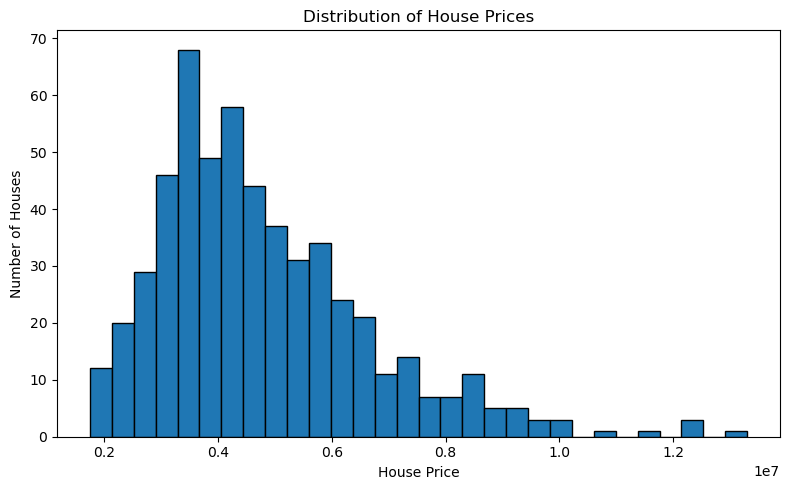

In [11]:
plt.figure(figsize=(8, 5))

plt.hist(df["price"], bins=30, edgecolor="black")

plt.title("Distribution of House Prices")
plt.xlabel("House Price")
plt.ylabel("Number of Houses")

plt.tight_layout()
plt.show()

In [12]:
df.dtypes

price                int64
area                 int64
bedrooms             int64
bathrooms            int64
stories              int64
mainroad            object
guestroom           object
basement            object
hotwaterheating     object
airconditioning     object
parking              int64
prefarea            object
furnishingstatus    object
dtype: object

In [13]:
X = df.drop(columns=["price"])
y = df["price"]

X = pd.get_dummies(X, drop_first=True, dtype=int)

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print(X.head())

Features shape: (545, 13)
Target shape: (545,)
   area  bedrooms  bathrooms  stories  parking  mainroad_yes  guestroom_yes  \
0  7420         4          2        3        2             1              0   
1  8960         4          4        4        3             1              0   
2  9960         3          2        2        2             1              0   
3  7500         4          2        2        3             1              0   
4  7420         4          1        2        2             1              1   

   basement_yes  hotwaterheating_yes  airconditioning_yes  prefarea_yes  \
0             0                    0                    1             1   
1             0                    0                    1             0   
2             1                    0                    0             1   
3             1                    0                    1             1   
4             1                    0                    1             0   

   furnishingstatus_semi-fu

In [14]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

In [16]:
y_pred = model.predict(X_test)

print("Predictions generated successfully.")

Predictions generated successfully.


In [17]:
results_df = pd.DataFrame({
    "Actual_Price": y_test,
    "Predicted_Price": y_pred
})

results_df["Prediction_Error"] = (
    results_df["Actual_Price"] -
    results_df["Predicted_Price"]
)

results_df["Absolute_Error"] = (
    results_df["Prediction_Error"].abs()
)

results_df = results_df.reset_index(drop=True)

results_df = results_df.round(2)

results_df.head(10)

,Actual_Price,Predicted_Price,Prediction_Error,Absolute_Error
0,4060000,5164653.90,-1104653.90,1104653.90
1,6650000,7224722.30,-574722.30,574722.30
2,3710000,3109863.24,600136.76,600136.76
3,6440000,4612075.33,1827924.67,1827924.67
4,2800000,3294646.26,-494646.26,494646.26
5,4900000,3532275.10,1367724.90,1367724.90
6,5250000,5611774.57,-361774.57,361774.57
7,4543000,6368145.99,-1825145.99,1825145.99
8,2450000,2722856.96,-272856.96,272856.96
9,3353000,2629405.62,723594.38,723594.38


In [18]:
r2 = r2_score(y_test, y_pred)

mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

print("=" * 45)
print("LINEAR REGRESSION MODEL EVALUATION")
print("=" * 45)

print(f"R² Score: {r2:.4f}")
print(f"Mean Absolute Error (MAE): {mae:,.2f}")
print(f"Mean Squared Error (MSE): {mse:,.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:,.2f}")

print("=" * 45)

LINEAR REGRESSION MODEL EVALUATION
R² Score: 0.6529
Mean Absolute Error (MAE): 970,043.40
Mean Squared Error (MSE): 1,754,318,687,330.66
Root Mean Squared Error (RMSE): 1,324,506.96


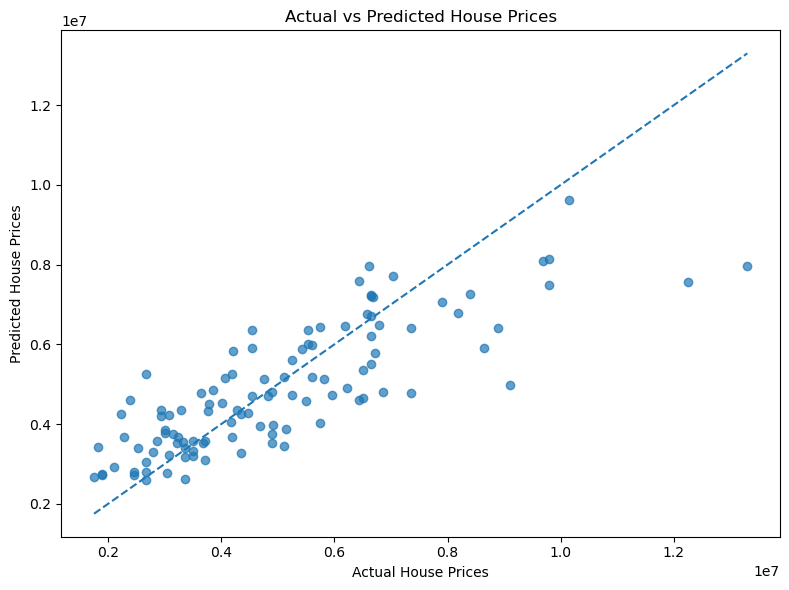

In [19]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.7)

# Perfect prediction reference line
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.xlabel("Actual House Prices")
plt.ylabel("Predicted House Prices")
plt.title("Actual vs Predicted House Prices")
plt.tight_layout()
plt.show()